# 04 · Ingeniería de Características — Savia Salud EPS

**Fase 3 del proyecto** · Objetivo: Construir el vector de features final para el modelo predictivo multiclase.

**Entrada:** `data/processed/20260304_dataset_entrenamiento.parquet` (728,289 filas × 39 columnas)  
**Salida:** Splits temporales en `data/processed/20260309_{train,val,test}.parquet`

## Pasos
1. Cargar dataset y diagnóstico de columnas
2. Eliminar columnas sin varianza y no-features
3. Imputar NaNs en variables de detalles (facturas sin líneas)
4. Transformaciones (log, flags, ratios)
5. Features de interacción
6. División temporal train / val / test (por `fecha_radicacion`)
7. Resumen del vector de features final
8. Guardar splits

## Hallazgos del EDA que guían esta fase
- Top 5 Spearman con target: `tasa_glosa_nit` (+0.349), `dias_hasta_radicacion` (+0.289), `porcentaje_mayor_item` (+0.276), `valor_factura` (+0.234), `num_items` (+0.146)
- Variables con varianza cero: `num_items_pbs`, `num_ambitos_distintos`, `origen_factura`
- Variables financieras altamente sesgadas → candidatas a log-transform

In [1]:
# Celda 1 — Configuración e imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Configuración global de gráficos ──────────────────────────
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.alpha': 0.4,
})

PALETTE = {0: '#27ae60', 1: '#e67e22', 2: '#e74c3c'}
LABELS  = {0: 'Auditada', 1: 'Glosada', 2: 'Devuelta'}
COLORS  = [PALETTE[k] for k in sorted(PALETTE)]

# ── Rutas ──────────────────────────────────────────────────────
BASE_DIR    = Path(r'D:\Users\jcardonr\Documents\eafit\Codigo')
DATA_FILE   = BASE_DIR / 'data' / 'processed' / '20260304_dataset_entrenamiento.parquet'
OUTPUT_DIR  = BASE_DIR / 'data' / 'processed'
FIGURES_DIR = BASE_DIR / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

def save_fig(name: str):
    """Guarda la figura activa en reports/figures/ a 300 dpi."""
    path = FIGURES_DIR / name
    plt.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f'  Guardado: {path.name}')

print('✅ Configuración lista')
print(f'   Dataset: {DATA_FILE.name}')
print(f'   Salida:  {OUTPUT_DIR}')

✅ Configuración lista
   Dataset: 20260304_dataset_entrenamiento.parquet
   Salida:  D:\Users\jcardonr\Documents\eafit\Codigo\data\processed


In [2]:
# Celda 2 — Cargar dataset y diagnóstico de columnas
df = pd.read_parquet(DATA_FILE)

print('=' * 65)
print('DATASET ORIGINAL — DIAGNÓSTICO DE COLUMNAS')
print('=' * 65)
print(f'Filas:    {len(df):,}')
print(f'Columnas: {len(df.columns)}')

# ── Clasificar columnas por rol ──────────────────────────────
# Columnas que NO son features (IDs, strings, fechas raw, target, redundantes)
DROP_NON_FEATURES = [
    'factura_id',              # Llave primaria — no es feature
    'nit_prestador',           # String ID — ya representado por features del NIT
    'tipo_contrato_codigo',    # String — usar tipo_contrato_encoded
    'tipo_contrato',           # String — usar tipo_contrato_encoded
    'regimen_codigo',          # String — usar regimen_encoded
    'regimen',                 # String — usar regimen_encoded
    'pbs',                     # Object/string — sin varianza útil observable en EDA
    'valor_factura_original',  # Redundante con valor_factura (winsorizada)
]

# Columnas con varianza cero (confirmado en EDA celda 2)
DROP_ZERO_VARIANCE = [
    'num_items_pbs',           # Siempre 0 en todo el dataset
    'num_ambitos_distintos',   # Siempre 0 en todo el dataset
    'origen_factura',          # Siempre 3 en todo el dataset
]

# Fechas: se conservan para la división temporal, pero se eliminan del feature vector final
DATE_COLS = ['fecha_prestacion', 'fecha_radicacion']

# Verificar varianza cero
print('\n── Verificación de varianza cero ──')
for col in DROP_ZERO_VARIANCE:
    nunique = df[col].nunique()
    print(f'  {col}: {nunique} valor(es) único(s) → {"ELIMINAR" if nunique <= 1 else "REVISAR"}')

# Verificar tipo_contrato_encoded para valor -1
print('\n── Diagnóstico tipo_contrato_encoded ──')
print(df['tipo_contrato_encoded'].value_counts().sort_index())
n_minus1 = (df['tipo_contrato_encoded'] == -1).sum()
print(f'  Valores -1 (posible missing): {n_minus1:,} ({n_minus1/len(df)*100:.2f}%)')

# Resumen de nulos
print('\n── Nulos por columna ──')
nulls = df.isnull().sum()
nulls = nulls[nulls > 0]
if len(nulls) > 0:
    for col, n in nulls.items():
        print(f'  {col}: {n:,} ({n/len(df)*100:.2f}%)')
else:
    print('  Sin nulos.')

# Facturas sin detalles
n_sin_items = (df['num_items'] == 0).sum()
print(f'\n── Facturas sin items (num_items=0): {n_sin_items:,} ({n_sin_items/len(df)*100:.2f}%) ──')
print('  Estas facturas tienen 0 en todas las variables de cm_detalles.')

print(f'\nColumnas a eliminar: {len(DROP_NON_FEATURES) + len(DROP_ZERO_VARIANCE)} de {len(df.columns)}')
print(f'  No-features: {DROP_NON_FEATURES}')
print(f'  Varianza cero: {DROP_ZERO_VARIANCE}')

DATASET ORIGINAL — DIAGNÓSTICO DE COLUMNAS
Filas:    728,289
Columnas: 39

── Verificación de varianza cero ──
  num_items_pbs: 1 valor(es) único(s) → ELIMINAR
  num_ambitos_distintos: 1 valor(es) único(s) → ELIMINAR
  origen_factura: 1 valor(es) único(s) → ELIMINAR

── Diagnóstico tipo_contrato_encoded ──
tipo_contrato_encoded
-1      8496
 0      3833
 1    715960
Name: count, dtype: int64
  Valores -1 (posible missing): 8,496 (1.17%)

── Nulos por columna ──
  Sin nulos.

── Facturas sin items (num_items=0): 39 (0.01%) ──
  Estas facturas tienen 0 en todas las variables de cm_detalles.

Columnas a eliminar: 11 de 39
  No-features: ['factura_id', 'nit_prestador', 'tipo_contrato_codigo', 'tipo_contrato', 'regimen_codigo', 'regimen', 'pbs', 'valor_factura_original']
  Varianza cero: ['num_items_pbs', 'num_ambitos_distintos', 'origen_factura']


In [3]:
# Celda 3 — Eliminar columnas sin varianza y no-features
# Conservamos factura_id y fechas temporalmente (necesarias para split y trazabilidad)

cols_to_drop = DROP_NON_FEATURES + DROP_ZERO_VARIANCE
# Solo eliminar las que existen en el dataset
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

df_fe = df.drop(columns=cols_to_drop).copy()

print('=' * 65)
print('PASO 1: ELIMINACIÓN DE COLUMNAS')
print('=' * 65)
print(f'Columnas eliminadas ({len(cols_to_drop)}):')
for c in cols_to_drop:
    print(f'  ✗ {c}')

print(f'\nColumnas restantes: {len(df_fe.columns)}')
print(f'  - target (variable objetivo)')
print(f'  - fecha_prestacion, fecha_radicacion (para split temporal, se eliminan después)')
print(f'  - {len(df_fe.columns) - 3} features candidatas')

# Listar features numéricas vs categóricas restantes
num_cols = df_fe.select_dtypes(include='number').columns.tolist()
num_cols = [c for c in num_cols if c != 'target']
print(f'\nFeatures numéricas ({len(num_cols)}):')
for c in num_cols:
    print(f'  {c}: {df_fe[c].dtype}')

date_cols = df_fe.select_dtypes(include='datetime').columns.tolist()
print(f'\nFechas ({len(date_cols)}): {date_cols}')

PASO 1: ELIMINACIÓN DE COLUMNAS
Columnas eliminadas (11):
  ✗ factura_id
  ✗ nit_prestador
  ✗ tipo_contrato_codigo
  ✗ tipo_contrato
  ✗ regimen_codigo
  ✗ regimen
  ✗ pbs
  ✗ valor_factura_original
  ✗ num_items_pbs
  ✗ num_ambitos_distintos
  ✗ origen_factura

Columnas restantes: 28
  - target (variable objetivo)
  - fecha_prestacion, fecha_radicacion (para split temporal, se eliminan después)
  - 25 features candidatas

Features numéricas (25):
  valor_factura: float64
  valor_copago: float64
  valor_cuota_moderadora: float64
  dias_hasta_radicacion: int64
  mes_radicacion: int64
  trimestre_radicacion: int64
  anio_radicacion: int64
  num_items: float64
  num_cups_distintos: float64
  sum_valor_facturado: float64
  max_valor_item: float64
  avg_valor_item: float64
  num_items_con_autorizacion: float64
  num_tipos_servicio: float64
  total_facturas_nit: int64
  tasa_devolucion_nit: float64
  tasa_glosa_nit: float64
  valor_promedio_nit: float64
  dias_radicacion_promedio_nit: float

In [4]:
# Celda 4 — Imputación de NaNs para facturas sin detalles en cm_detalles
# Las facturas con num_items=0 no tienen líneas en cm_detalles.
# Todas sus variables agregadas de detalles son 0, no NaN (por la query con COALESCE).
# Pero verificamos e imputamos por seguridad.

# Variables que provienen de cm_detalles (pueden ser 0 legítimos o NaN)
DETAIL_COLS = [
    'num_items', 'num_cups_distintos', 'num_dx_distintos',
    'sum_valor_facturado', 'max_valor_item', 'avg_valor_item',
    'num_items_con_autorizacion', 'num_tipos_servicio',
]

print('=' * 65)
print('PASO 2: IMPUTACIÓN DE VALORES')
print('=' * 65)

# Verificar NaNs en variables de detalles
for col in DETAIL_COLS:
    if col in df_fe.columns:
        n_nan = df_fe[col].isna().sum()
        n_zero = (df_fe[col] == 0).sum()
        if n_nan > 0:
            print(f'  {col}: {n_nan:,} NaN → imputar con 0')
            df_fe[col] = df_fe[col].fillna(0)
        else:
            print(f'  {col}: sin NaN ({n_zero:,} zeros)')

# Verificar NaNs en variables del prestador (NIT)
NIT_COLS = ['total_facturas_nit', 'tasa_devolucion_nit', 'tasa_glosa_nit',
            'valor_promedio_nit', 'dias_radicacion_promedio_nit']

print('\nVariables del prestador:')
for col in NIT_COLS:
    if col in df_fe.columns:
        n_nan = df_fe[col].isna().sum()
        if n_nan > 0:
            # Imputar con la mediana (prestadores nuevos sin historial)
            median_val = df_fe[col].median()
            df_fe[col] = df_fe[col].fillna(median_val)
            print(f'  {col}: {n_nan:,} NaN → imputar con mediana ({median_val:.2f})')
        else:
            print(f'  {col}: sin NaN')

# Verificación final
total_nan = df_fe.select_dtypes(include='number').isna().sum().sum()
print(f'\n✅ Total NaN en features numéricas después de imputación: {total_nan}')

PASO 2: IMPUTACIÓN DE VALORES
  num_items: sin NaN (39 zeros)
  num_cups_distintos: sin NaN (39 zeros)
  num_dx_distintos: sin NaN (71,783 zeros)
  sum_valor_facturado: sin NaN (479 zeros)
  max_valor_item: sin NaN (478 zeros)
  avg_valor_item: sin NaN (479 zeros)
  num_items_con_autorizacion: sin NaN (410,848 zeros)
  num_tipos_servicio: sin NaN (39 zeros)

Variables del prestador:
  total_facturas_nit: sin NaN
  tasa_devolucion_nit: sin NaN
  tasa_glosa_nit: sin NaN
  valor_promedio_nit: sin NaN
  dias_radicacion_promedio_nit: sin NaN

✅ Total NaN en features numéricas después de imputación: 0


In [5]:
# Celda 5 — Transformaciones: log, flags y ratios
# Las variables financieras y de conteo tienen distribuciones muy sesgadas (EDA celda 2).
# Aplicar log1p(x) = log(1 + x) para reducir el sesgo sin perder los ceros.

print('=' * 65)
print('PASO 3: TRANSFORMACIONES')
print('=' * 65)

# ── 5A. Transformación log1p para variables sesgadas ─────────
LOG_COLS = [
    'valor_factura',           # Mediana $152K, max $348M → altamente sesgada
    'valor_copago',            # Muchos 0, algunos altos
    'valor_cuota_moderadora',  # Muchos 0, algunos altos
    'num_items',               # Mediana 1, max 490K
    'num_cups_distintos',      # Mediana 1, max 1486
    'num_dx_distintos',        # Mediana 1, max 2531
    'sum_valor_facturado',     # Similar a valor_factura
    'max_valor_item',          # Altamente sesgada
    'avg_valor_item',          # Altamente sesgada
    'num_items_con_autorizacion',  # Mediana 0, max 13K
    'total_facturas_nit',      # Mediana 52K, max 641K
    'valor_promedio_nit',      # Altamente sesgada
    'discrepancia_valor',      # Mediana 0, max muy alto
]

print('Variables con transformación log1p:')
for col in LOG_COLS:
    if col not in df_fe.columns:
        continue
    new_col = f'log_{col}'
    df_fe[new_col] = np.log1p(df_fe[col])
    skew_before = df_fe[col].skew()
    skew_after = df_fe[new_col].skew()
    print(f'  {col:35s} → {new_col:40s}  skew: {skew_before:>8.1f} → {skew_after:>6.1f}')

# ── 5B. Flag: radicación extemporánea (>22 días hábiles) ────
# Base regulatoria: Resolución 2284/2023, causal DE16
df_fe['is_extemporanea'] = (df_fe['dias_hasta_radicacion'] > 22).astype(np.int8)
pct_ext = df_fe['is_extemporanea'].mean() * 100
print(f'\n  is_extemporanea (>22 días): {pct_ext:.1f}% de las facturas')

# ── 5C. Flag: factura con valor de copago o cuota moderadora ─
df_fe['tiene_copago'] = (df_fe['valor_copago'] > 0).astype(np.int8)
df_fe['tiene_cuota_mod'] = (df_fe['valor_cuota_moderadora'] > 0).astype(np.int8)
print(f'  tiene_copago:    {df_fe["tiene_copago"].mean()*100:.1f}%')
print(f'  tiene_cuota_mod: {df_fe["tiene_cuota_mod"].mean()*100:.1f}%')

# ── 5D. Flag: factura sin detalles en cm_detalles ───────────
df_fe['sin_detalles'] = (df_fe['num_items'] == 0).astype(np.int8)
print(f'  sin_detalles:    {df_fe["sin_detalles"].mean()*100:.2f}%')

print(f'\nColumnas después de transformaciones: {len(df_fe.columns)}')

PASO 3: TRANSFORMACIONES
Variables con transformación log1p:
  valor_factura                       → log_valor_factura                         skew:     13.0 →    0.8
  valor_copago                        → log_valor_copago                          skew:    124.7 →    3.9
  valor_cuota_moderadora              → log_valor_cuota_moderadora                skew:    106.8 →    4.2
  num_items                           → log_num_items                             skew:    143.2 →    1.6
  num_cups_distintos                  → log_num_cups_distintos                    skew:      9.5 →    1.3
  num_dx_distintos                    → log_num_dx_distintos                      skew:     41.3 →    5.9
  sum_valor_facturado                 → log_sum_valor_facturado                   skew:    518.9 →    0.6
  max_valor_item                      → log_max_valor_item                        skew:    653.0 →    0.3
  avg_valor_item                      → log_avg_valor_item                        skew:    

In [6]:
# Celda 6 — Features de interacción
# Combinaciones motivadas por hallazgos del EDA y lógica de negocio.

print('=' * 65)
print('PASO 4: FEATURES DE INTERACCIÓN')
print('=' * 65)

# ── 6A. Ratio valor factura vs promedio del NIT ─────────────
# Lógica: una factura con valor muy superior al promedio histórico del prestador
# es más sospechosa. Base: análisis de outliers del EDA.
df_fe['ratio_valor_vs_nit'] = np.where(
    df_fe['valor_promedio_nit'] > 0,
    df_fe['valor_factura'] / df_fe['valor_promedio_nit'],
    0
)
# Clipear outliers extremos del ratio
df_fe['ratio_valor_vs_nit'] = df_fe['ratio_valor_vs_nit'].clip(0, 100)
print(f'  ratio_valor_vs_nit: mediana={df_fe["ratio_valor_vs_nit"].median():.2f}, p99={df_fe["ratio_valor_vs_nit"].quantile(0.99):.1f}')

# ── 6B. Interacción valor × tasa_glosa_nit ──────────────────
# Lógica: facturas de alto valor en prestadores con historial de glosa
# tienen riesgo compuesto. Usar versiones log para estabilidad.
df_fe['log_valor_x_tasa_glosa'] = df_fe['log_valor_factura'] * df_fe['tasa_glosa_nit']
print(f'  log_valor_x_tasa_glosa: mediana={df_fe["log_valor_x_tasa_glosa"].median():.1f}')

# ── 6C. Interacción días × valor ────────────────────────────
# Lógica: facturas con radicación tardía Y alto valor generan mayor riesgo.
df_fe['dias_x_log_valor'] = df_fe['dias_hasta_radicacion'] * df_fe['log_valor_factura']
print(f'  dias_x_log_valor: mediana={df_fe["dias_x_log_valor"].median():.1f}')

# ── 6D. Ratio items con autorización / total items ──────────
# Lógica: % de ítems que requieren autorización previa. Base regulatoria:
# ítems sin autorización en contrato Evento son causal de glosa (FA).
df_fe['ratio_autorizacion'] = np.where(
    df_fe['num_items'] > 0,
    df_fe['num_items_con_autorizacion'] / df_fe['num_items'],
    0
)
df_fe['ratio_autorizacion'] = df_fe['ratio_autorizacion'].clip(0, 1)
print(f'  ratio_autorizacion: mediana={df_fe["ratio_autorizacion"].median():.3f}')

# ── 6E. Desviación de días de radicación vs promedio del NIT ─
# Lógica: una factura que tarda más que lo habitual del prestador
# puede indicar problemas en la documentación.
df_fe['desviacion_dias_nit'] = np.where(
    df_fe['dias_radicacion_promedio_nit'] > 0,
    df_fe['dias_hasta_radicacion'] / df_fe['dias_radicacion_promedio_nit'],
    1
)
df_fe['desviacion_dias_nit'] = df_fe['desviacion_dias_nit'].clip(0, 50)
print(f'  desviacion_dias_nit: mediana={df_fe["desviacion_dias_nit"].median():.2f}')

# ── 6F. Diversidad de servicios (ratio CUPS distintos / items) ─
# Lógica: facturas con muchos ítems pero pocos CUPS distintos indican
# repetición de servicios (posible duplicidad — causal FA0301).
df_fe['ratio_cups_items'] = np.where(
    df_fe['num_items'] > 0,
    df_fe['num_cups_distintos'] / df_fe['num_items'],
    0
)
df_fe['ratio_cups_items'] = df_fe['ratio_cups_items'].clip(0, 1)
print(f'  ratio_cups_items: mediana={df_fe["ratio_cups_items"].median():.3f}')

print(f'\nFeatures de interacción creadas: 6')
print(f'Columnas totales: {len(df_fe.columns)}')

PASO 4: FEATURES DE INTERACCIÓN
  ratio_valor_vs_nit: mediana=0.26, p99=22.4
  log_valor_x_tasa_glosa: mediana=185.3
  dias_x_log_valor: mediana=241.2
  ratio_autorizacion: mediana=0.000
  desviacion_dias_nit: mediana=0.60
  ratio_cups_items: mediana=1.000

Features de interacción creadas: 6
Columnas totales: 51


In [7]:
# Celda 7 — División temporal train / val / test
# CRÍTICO: División por fecha_radicacion (NO aleatoria) para prevenir data leakage.
# Protocolo CLAUDE.MD §4 Fase 4:
#   Train: facturas del período T-12 a T-2
#   Val:   facturas del período T-2 a T-1
#   Test:  facturas del mes T (último mes disponible)

print('=' * 65)
print('PASO 5: DIVISIÓN TEMPORAL TRAIN / VAL / TEST')
print('=' * 65)

# Asegurar que fecha_radicacion sea datetime
df_fe['fecha_radicacion'] = pd.to_datetime(df_fe['fecha_radicacion'])

# Determinar rango temporal
fecha_min = df_fe['fecha_radicacion'].min()
fecha_max = df_fe['fecha_radicacion'].max()
print(f'Rango temporal: {fecha_min.date()} → {fecha_max.date()}')

# Calcular cortes temporales
# T = último mes completo, T-1 = penúltimo, etc.
# Usar el último día del penúltimo mes como corte de test
ultimo_mes = fecha_max.to_period('M')
penultimo_mes = ultimo_mes - 1
antepenultimo_mes = ultimo_mes - 2

# Cortes
corte_test = penultimo_mes.to_timestamp()       # Test: último mes completo y después
corte_val  = antepenultimo_mes.to_timestamp()    # Val: penúltimo mes

print(f'\nCortes temporales:')
print(f'  Train: {fecha_min.date()} → {(corte_val - pd.Timedelta(days=1)).date()}')
print(f'  Val:   {corte_val.date()} → {(corte_test - pd.Timedelta(days=1)).date()}')
print(f'  Test:  {corte_test.date()} → {fecha_max.date()}')

# Aplicar división
mask_train = df_fe['fecha_radicacion'] < corte_val
mask_val   = (df_fe['fecha_radicacion'] >= corte_val) & (df_fe['fecha_radicacion'] < corte_test)
mask_test  = df_fe['fecha_radicacion'] >= corte_test

print(f'\n  Train: {mask_train.sum():>8,} facturas ({mask_train.mean()*100:.1f}%)')
print(f'  Val:   {mask_val.sum():>8,} facturas ({mask_val.mean()*100:.1f}%)')
print(f'  Test:  {mask_test.sum():>8,} facturas ({mask_test.mean()*100:.1f}%)')

# Distribución de clases por split
print('\nDistribución de clases por split:')
for nombre, mask in [('Train', mask_train), ('Val', mask_val), ('Test', mask_test)]:
    dist = df_fe.loc[mask, 'target'].value_counts().sort_index()
    total = dist.sum()
    parts = '  '.join([f'{LABELS[c]}: {cnt:,} ({cnt/total*100:.1f}%)' for c, cnt in dist.items()])
    print(f'  {nombre}: {parts}')

PASO 5: DIVISIÓN TEMPORAL TRAIN / VAL / TEST
Rango temporal: 2024-03-04 → 2026-03-04

Cortes temporales:
  Train: 2024-03-04 → 2025-12-31
  Val:   2026-01-01 → 2026-01-31
  Test:  2026-02-01 → 2026-03-04

  Train:  705,633 facturas (96.9%)
  Val:     12,639 facturas (1.7%)
  Test:    10,017 facturas (1.4%)

Distribución de clases por split:
  Train: Auditada: 169,695 (24.0%)  Glosada: 400,000 (56.7%)  Devuelta: 135,938 (19.3%)
  Val: Auditada: 9,192 (72.7%)  Devuelta: 3,447 (27.3%)
  Test: Auditada: 9,689 (96.7%)  Devuelta: 328 (3.3%)


In [8]:
# Celda 8 — Definir vector de features final y eliminar columnas auxiliares
# Eliminar: fechas, columnas originales que ya tienen versión log (conservar ambas
# para que XGBoost pueda usar la que mejor discrimine).

print('=' * 65)
print('PASO 6: VECTOR DE FEATURES FINAL')
print('=' * 65)

# Columnas a eliminar del feature vector (NO son features)
REMOVE_FROM_FEATURES = ['fecha_prestacion', 'fecha_radicacion', 'target']

# Todas las columnas excepto las de arriba son features
feature_cols = [c for c in df_fe.columns if c not in REMOVE_FROM_FEATURES]
feature_cols.sort()

print(f'Features finales: {len(feature_cols)}')
print(f'\nListado completo:')
for i, col in enumerate(feature_cols, 1):
    dtype = df_fe[col].dtype
    nunique = df_fe[col].nunique()
    print(f'  {i:2d}. {col:<40s}  {str(dtype):<10s}  unique={nunique:,}')

# Verificar que no hay leakage
LEAKAGE_COLS = ['ejecucion_glosa_aut_ia', 'estado_glosa_aut', 'valor_inicial_glosa',
                'valor_pagado_factura', 'estado_factura']
leakage_found = [c for c in LEAKAGE_COLS if c in feature_cols]
if leakage_found:
    print(f'\n⚠️ ALERTA DE LEAKAGE: {leakage_found}')
else:
    print(f'\n✅ Sin columnas de leakage detectadas')

# Verificar NaN en features
nan_check = df_fe[feature_cols].isna().sum()
nan_total = nan_check.sum()
print(f'✅ NaN totales en features: {nan_total}')

PASO 6: VECTOR DE FEATURES FINAL
Features finales: 48

Listado completo:
   1. anio_radicacion                           int64       unique=3
   2. avg_valor_item                            float64     unique=261,405
   3. desviacion_dias_nit                       float64     unique=22,396
   4. dias_hasta_radicacion                     int64       unique=366
   5. dias_radicacion_promedio_nit              float64     unique=642
   6. dias_x_log_valor                          float64     unique=395,909
   7. discrepancia_valor                        float64     unique=14,151
   8. is_extemporanea                           int8        unique=2
   9. log_avg_valor_item                        float64     unique=261,405
  10. log_discrepancia_valor                    float64     unique=14,151
  11. log_max_valor_item                        float64     unique=55,334
  12. log_num_cups_distintos                    float64     unique=609
  13. log_num_dx_distintos                      float64

  Guardado: fe_01_correlaciones_features.png


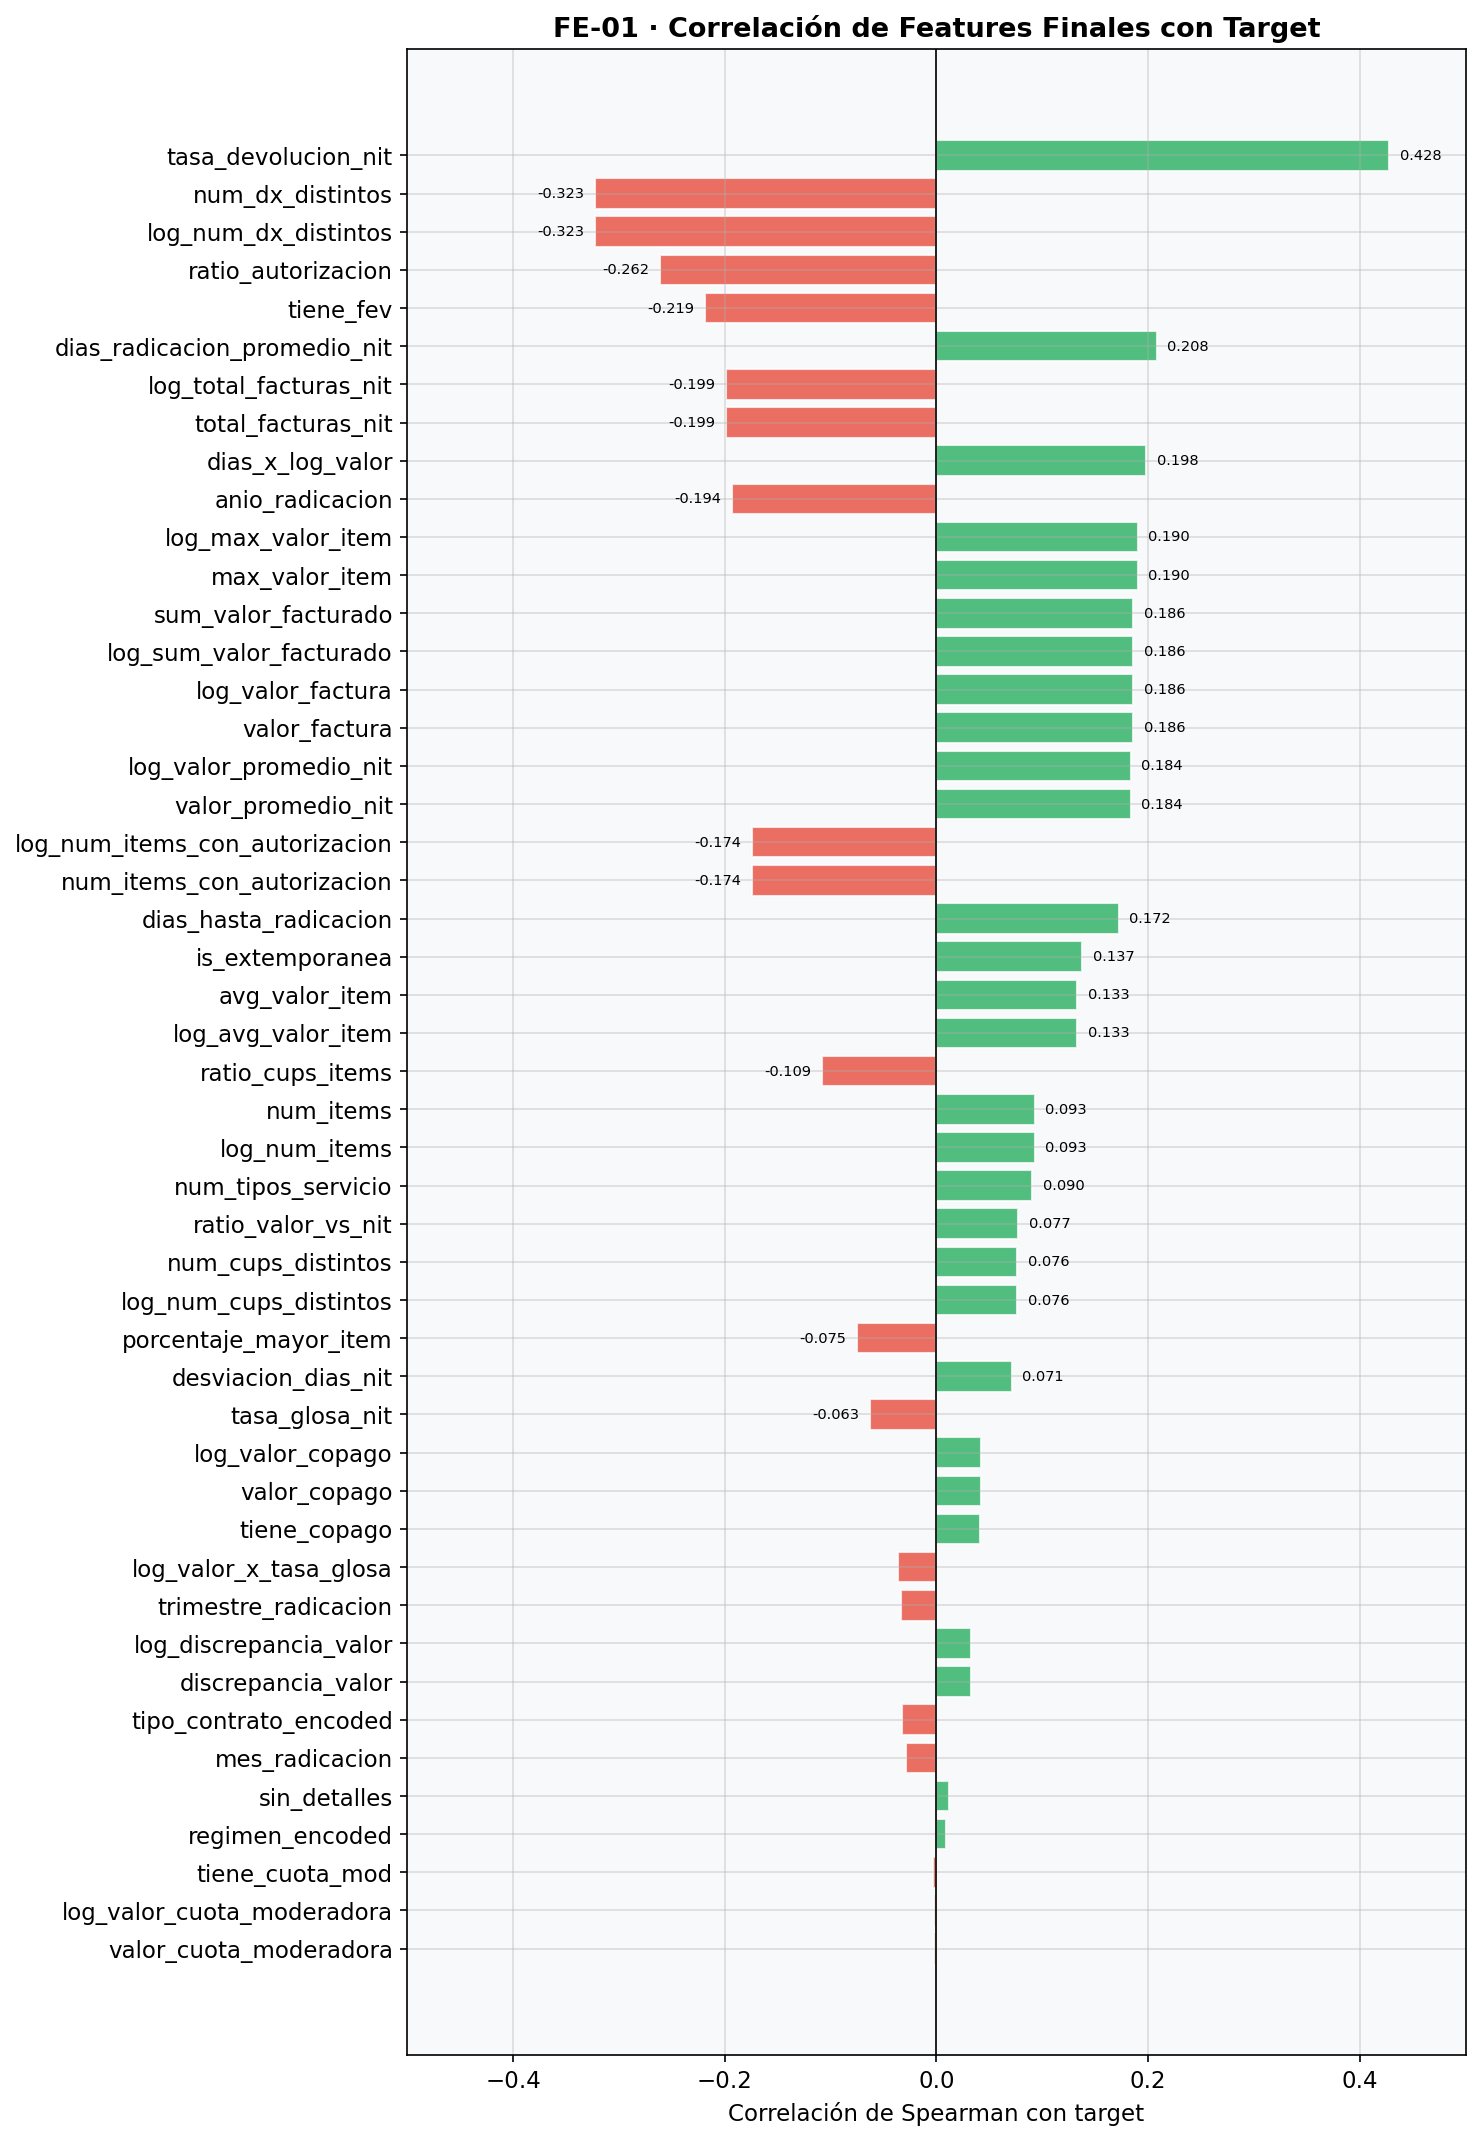


Top 10 features más correlacionadas con target:
  +0.428  tasa_devolucion_nit
  -0.323  num_dx_distintos
  -0.323  log_num_dx_distintos
  -0.262  ratio_autorizacion
  -0.219  tiene_fev
  +0.208  dias_radicacion_promedio_nit
  -0.199  log_total_facturas_nit
  -0.199  total_facturas_nit
  +0.198  dias_x_log_valor
  -0.194  anio_radicacion


In [9]:
# Celda 9 — Correlaciones del feature vector con target (figura para tesis)

# Correlación Spearman de todas las features con target
corr_target = df_fe[feature_cols + ['target']].corr(method='spearman')['target'].drop('target')
corr_target = corr_target.reindex(corr_target.abs().sort_values(ascending=True).index)

fig, ax = plt.subplots(figsize=(10, max(8, len(feature_cols) * 0.3)))
colors = ['#e74c3c' if v < 0 else '#27ae60' for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors, alpha=0.8, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlación de Spearman con target')
ax.set_title('FE-01 · Correlación de Features Finales con Target', fontweight='bold')
ax.set_xlim(-0.5, 0.5)

# Anotar valores en las barras más relevantes
for i, (col, val) in enumerate(corr_target.items()):
    if abs(val) > 0.05:
        ax.text(val + (0.01 if val > 0 else -0.01), i,
                f'{val:.3f}', va='center', ha='left' if val > 0 else 'right', fontsize=7)

plt.tight_layout()
save_fig('fe_01_correlaciones_features.png')
plt.show()

# Top 10 features más correlacionadas
print('\nTop 10 features más correlacionadas con target:')
top10 = corr_target.abs().sort_values(ascending=False).head(10)
for col in top10.index:
    val = corr_target[col]
    print(f'  {"+" if val > 0 else ""}{val:.3f}  {col}')

In [10]:
# Celda 10 — Guardar splits en Parquet
# Formato: data/processed/20260309_{train,val,test}.parquet
# Cada archivo contiene: features + target + factura_id (para trazabilidad)

print('=' * 65)
print('PASO 7: GUARDAR SPLITS')
print('=' * 65)

# Recuperar factura_id del dataset original para trazabilidad
df_fe['factura_id'] = df['factura_id'].values

# Columnas a guardar: factura_id (trazabilidad) + target + features
save_cols = ['factura_id', 'target'] + feature_cols

# Crear los DataFrames de cada split
df_train = df_fe.loc[mask_train, save_cols].reset_index(drop=True)
df_val   = df_fe.loc[mask_val,   save_cols].reset_index(drop=True)
df_test  = df_fe.loc[mask_test,  save_cols].reset_index(drop=True)

# Guardar
prefix = '20260309'
path_train = OUTPUT_DIR / f'{prefix}_train.parquet'
path_val   = OUTPUT_DIR / f'{prefix}_val.parquet'
path_test  = OUTPUT_DIR / f'{prefix}_test.parquet'

df_train.to_parquet(path_train, index=False)
df_val.to_parquet(path_val, index=False)
df_test.to_parquet(path_test, index=False)

for name, path, dframe in [('Train', path_train, df_train),
                            ('Val', path_val, df_val),
                            ('Test', path_test, df_test)]:
    size_mb = path.stat().st_size / 1024 / 1024
    print(f'  {name:5s}: {path.name}')
    print(f'         {len(dframe):>8,} filas × {len(dframe.columns)} cols  ({size_mb:.1f} MB)')

# Guardar también la lista de features como referencia
feature_list_path = OUTPUT_DIR / f'{prefix}_feature_list.txt'
with open(feature_list_path, 'w') as f:
    f.write('\n'.join(feature_cols))
print(f'\n  Lista de features: {feature_list_path.name} ({len(feature_cols)} features)')

print('\n✅ Splits guardados exitosamente')

PASO 7: GUARDAR SPLITS
  Train: 20260309_train.parquet
          705,633 filas × 50 cols  (46.4 MB)
  Val  : 20260309_val.parquet
           12,639 filas × 50 cols  (0.9 MB)
  Test : 20260309_test.parquet
           10,017 filas × 50 cols  (0.7 MB)

  Lista de features: 20260309_feature_list.txt (48 features)

✅ Splits guardados exitosamente


In [11]:
# Celda 11 — Resumen final para tesis

print('=' * 70)
print('RESUMEN FASE 3 — FEATURE ENGINEERING')
print('=' * 70)

print(f'''
1. DATASET ORIGINAL
   Entrada: 20260304_dataset_entrenamiento.parquet
   Filas: {len(df):,} × {len(df.columns)} columnas

2. COLUMNAS ELIMINADAS ({len(cols_to_drop)})
   - No-features (IDs, strings, redundantes): {len(DROP_NON_FEATURES)}
   - Varianza cero: {len(DROP_ZERO_VARIANCE)} (num_items_pbs, num_ambitos_distintos, origen_factura)

3. TRANSFORMACIONES APLICADAS
   - log1p: {len(LOG_COLS)} variables financieras/conteo (reducción de skewness)
   - Flags binarios: is_extemporanea, tiene_copago, tiene_cuota_mod, sin_detalles

4. FEATURES DE INTERACCIÓN (6 nuevas)
   - ratio_valor_vs_nit:       factura vs promedio histórico del prestador
   - log_valor_x_tasa_glosa:   valor × tasa de glosa (riesgo compuesto)
   - dias_x_log_valor:         radicación tardía × alto valor
   - ratio_autorizacion:       % ítems con autorización previa
   - desviacion_dias_nit:      días vs promedio del prestador
   - ratio_cups_items:         diversidad de servicios

5. VECTOR DE FEATURES FINAL
   Total features: {len(feature_cols)}

6. DIVISIÓN TEMPORAL (sin leakage)
   Train: {mask_train.sum():,} ({mask_train.mean()*100:.1f}%)
   Val:   {mask_val.sum():,} ({mask_val.mean()*100:.1f}%)
   Test:  {mask_test.sum():,} ({mask_test.mean()*100:.1f}%)

7. ARCHIVOS GENERADOS
   data/processed/20260309_train.parquet
   data/processed/20260309_val.parquet
   data/processed/20260309_test.parquet
   data/processed/20260309_feature_list.txt
   reports/figures/fe_01_correlaciones_features.png

PRÓXIMO PASO → notebooks/05_Model_Training.ipynb (Fase 4)
''')

RESUMEN FASE 3 — FEATURE ENGINEERING

1. DATASET ORIGINAL
   Entrada: 20260304_dataset_entrenamiento.parquet
   Filas: 728,289 × 39 columnas

2. COLUMNAS ELIMINADAS (11)
   - No-features (IDs, strings, redundantes): 8
   - Varianza cero: 3 (num_items_pbs, num_ambitos_distintos, origen_factura)

3. TRANSFORMACIONES APLICADAS
   - log1p: 13 variables financieras/conteo (reducción de skewness)
   - Flags binarios: is_extemporanea, tiene_copago, tiene_cuota_mod, sin_detalles

4. FEATURES DE INTERACCIÓN (6 nuevas)
   - ratio_valor_vs_nit:       factura vs promedio histórico del prestador
   - log_valor_x_tasa_glosa:   valor × tasa de glosa (riesgo compuesto)
   - dias_x_log_valor:         radicación tardía × alto valor
   - ratio_autorizacion:       % ítems con autorización previa
   - desviacion_dias_nit:      días vs promedio del prestador
   - ratio_cups_items:         diversidad de servicios

5. VECTOR DE FEATURES FINAL
   Total features: 48

6. DIVISIÓN TEMPORAL (sin leakage)
   Train: